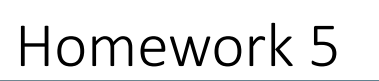

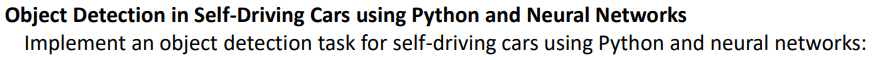

#**#1  IMPORTS - CRUCIAL LIBARIES**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from keras.optimizers import Adam
from keras.utils import to_categorical
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import pickle
import pandas as pd
import random
import cv2

#**#2 LOADING "KITTI" DATASET**

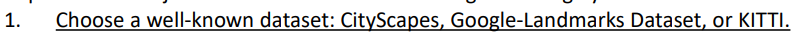

"*KITTI is a dataset for autonomous driving developed by the Karlsruhe Institute of Technology and Toyota Technological Institute at Chicago. It is a collection of images and LIDAR data used in computer vision research, such as stereo vision, optical flow, visual odometry, 3D object detection, and 3D tracking.*"

In [2]:
!wget 'https://s3.eu-central-1.amazonaws.com/avg-kitti/data_object_image_2.zip' # Obtaining the images
!wget 'https://s3.eu-central-1.amazonaws.com/avg-kitti/data_object_label_2.zip' # Obtaining the labels to each image
!unzip -qq data_object_image_2.zip # Unziping the downloaded folders
!unzip -qq data_object_label_2.zip
!rm data_object_image_2.zip data_object_label_2.zip  # Deleting the zips after extracting

zsh:1: command not found: wget
zsh:1: command not found: wget
unzip:  cannot find or open data_object_image_2.zip, data_object_image_2.zip.zip or data_object_image_2.zip.ZIP.
unzip:  cannot find or open data_object_label_2.zip, data_object_label_2.zip.zip or data_object_label_2.zip.ZIP.
rm: data_object_image_2.zip: No such file or directory
rm: data_object_label_2.zip: No such file or directory


\\
It is important to verify that the  dataset was downloaded correctly into this envvironmnent. My selected way of verification is chacking the sizes of the train and test sub-dataset. The actual measurements are provided online.

**Expected Results:**

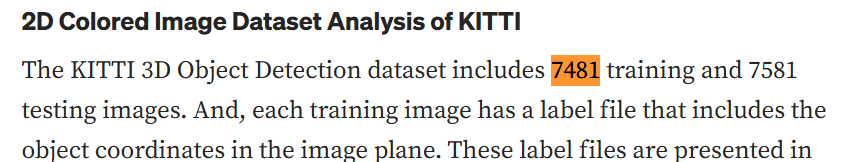

Source: https://medium.com/data-science/mastering-sensor-fusion-color-image-obstacle-detection-with-kitti-data-part-2-5118be4e92ee

In [3]:
import os
print("Number of training images:", len(os.listdir('training/image_2')))  # Path to the training images
print("Number of training labels:", len(os.listdir('training/label_2')))  # Path to testing images

Number of training images: 7481
Number of training labels: 7481


#**#3 PREPROCESSING THE DATASET**




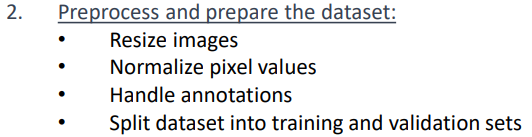

####1.   **Resize the images**


Resizing is an important operation that ensures that all input images have the same "standard" size.

Also, if dealing with large images, resizing them into smaller dimensions reduces the amount of data that is being processed, thus speedig up the training process.


In [4]:
target_size=(416,416)  # 416 x 416 pixels

# Resize Function
def resize(image_path, size):
  img=Image.open(image_path) # Open each image from the path
  return img.resize(size)


\\
Visualizing the resizing process by comparing the images to their original versions.

In [5]:
# Defining the paths
image_dir = 'training/image_2/'
label_dir = 'training/label_2/'


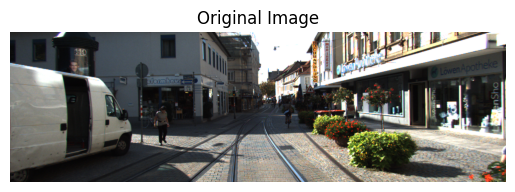

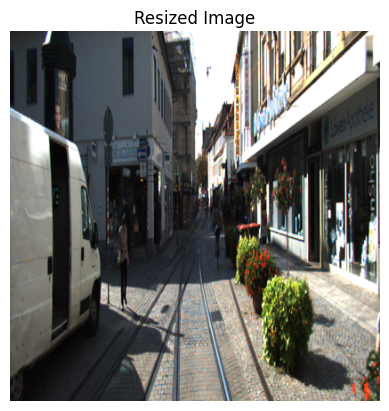

In [6]:
from PIL import Image

# Display the Original Image
or_img_path=os.path.join(image_dir,'000100.png') # Change "000001.png" to a diff. image title
org_img=Image.open(or_img_path)
plt.title("Original Image")
plt.imshow(org_img)
plt.axis('off')
plt.show()

# Display the Resized Image
res_img= resize(or_img_path, target_size)
plt.title("Resized Image")
plt.imshow(res_img)
plt.axis('off')
plt.show() # Result: 416 x 416 RGB image



####2.   **Creating the "*Training* Dataset"**



Defining a PyTorch dataset called the "train_dataset" for the purpose of loading KITTI (object-detection) images.

In [11]:
import os
import torch
from torch.utils.data import Dataset
from torchvision import transforms
from PIL import Image

class KITTIDataset(Dataset):
    def __init__(self, image_dir, label_dir, transform=None, train=True):
        self.image_dir = image_dir
        self.label_dir = label_dir
        self.image_filenames = sorted(os.listdir(image_dir))
        self.transform = transform
        self.train=train

        self.class_map = {
            'Car': 0,
            'Van': 1,
            'Truck': 2,
            'Pedestrian': 3,
            'Person_sitting': 4,
            'Cyclist': 5,
            'Tram': 6,
            'Misc': 7,
            'DontCare': -1
        }
        # Check if the directories exist
        if not os.path.exists(self.image_dir):
          raise FileNotFoundError(f"The specified image directory was NOT found! {self.image_dir}")
        if train and not os.path.exists(self.label_dir):
          raise FileNotFoundError(f"The specified label directory was NOT found! {self.label_dir}")

        # Check the list of available images in the directory
        self.image_filenames=[]
        if os.path.exists(self.image_dir):
          all_files=os.listdir(self.image_dir)
          self.image_filenames = [f for f in all_files if f.endswith('.png')]
          self.image_filenames.sort()

        if len(self.image_filenames)==0:
          raise RuntimeError(f"No PNG files were detected in {self.image_dir}")
        print(f"Found ({len(self.image_filenames)})PNG files in directory : {self.image_dir}")

    def __len__(self):
        return len(self.image_filenames)

    def __getitem__(self, idx):
        image_filename = self.image_filenames[idx]
        image_path = os.path.join(self.image_dir, image_filename)
        try:
          image = Image.open(image_path).convert('RGB')
        except Exception as e:
          raise RuntimeError(f"Failed to Load image {image_path}: {e}")

        # Save original dimensions - might go back for them
        orig_width, orig_height = image.size

        label_filename = image_filename.replace('.png', '.txt')
        label_path = os.path.join(self.label_dir, label_filename)

        boxes = []
        labels = []

        if os.path.exists(label_path):
            with open(label_path, 'r') as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) >= 8:
                        class_name = parts[0]
                        if class_name not in self.class_map:
                            continue
                        class_id = self.class_map[class_name]
                        if class_id == -1:  # Skip DontCare regions
                            continue
                        xmin, ymin, xmax, ymax = map(float, parts[4:8])
                        boxes.append([xmin, ymin, xmax, ymax])
                        labels.append(class_id)

        # Apply transform to image (e.g., resizing)
        if self.transform:
            image = self.transform(image)

        # Scale bounding boxes to resized image (416x416)
        target_width, target_height = 416, 416
        scale_x = target_width / orig_width
        scale_y = target_height / orig_height

        scaled_boxes = []
        for box in boxes:
            x1, y1, x2, y2 = box
            scaled_boxes.append([
                x1 * scale_x,
                y1 * scale_y,
                x2 * scale_x,
                y2 * scale_y
            ])

        # Convert to tensors
        boxes_tensor = torch.tensor(scaled_boxes, dtype=torch.float32) if scaled_boxes else torch.zeros((0, 4), dtype=torch.float32)
        labels_tensor = torch.tensor(labels, dtype=torch.int64) if labels else torch.zeros((0,), dtype=torch.int64)

        return image, {'boxes': boxes_tensor, 'labels': labels_tensor}



#### 3.   **Normalizing the images**

Normalizing scales the pixel values to [0,1], creating numeral stability.

This means images in the format [0,255] are converted into [0,1]



In [12]:
import torch
from torchvision import transforms


# KITTI-specific values = normalization values
mean= [0.3834, 0.3912, 0.3804]
std = [0.2519, 0.2535, 0.2550]


print("USING KITTI-SPECIFIC VALUES")
print(f"Mean: {mean}")
print(f"Standard Deviation: {std}")

# Create transform with standard values
transform = transforms.Compose([
    transforms.Resize(target_size),       # 1st Resize
    transforms.ToTensor(),                # 2nd Convert into Tensor
    transforms.Normalize(mean=mean, std=std), # 3rd Normalize with standard values
])

# Create datasets
train_dataset = KITTIDataset(image_dir=image_dir,
                            label_dir=label_dir,
                            transform=transform)

print(f"Dataset length: {len(train_dataset)}")

# Test loading a sample
try:
    sample_image, sample_label = train_dataset[0]
    print(f"\nSample image shape: {sample_image.shape}")
    print(f"Sample image range: [{sample_image.min():.3f}, {sample_image.max():.3f}]")
    print(f"Number of boxes in sample: {len(sample_label['boxes'])}")
    print("\nDataset loading  WAS successful!")
except Exception as e:
    print(f"\nDataset loading  WAS NOT successful! --- Error loading sample: {e}")


USING KITTI-SPECIFIC VALUES
Mean: [0.3834, 0.3912, 0.3804]
Standard Deviation: [0.2519, 0.2535, 0.255]
Found (7481)PNG files in directory : training/image_2/
Dataset length: 7481

Sample image shape: torch.Size([3, 416, 416])
Sample image range: [-1.522, 2.448]
Number of boxes in sample: 1

Dataset loading  WAS successful!



####4.   **Handling Annotations**




**Annotations** - extra information provided for the model specifying the objects in each image and their location. It inculdes:



*   **Class Labels**
*   **Bounding Boxes**


In the KITTI dataset annotations are provided in the *.txt* file and it corresponds to each image in the training dataset.

#####**HOW ARE ANNOTATIONS HANDELED HERE?**



1.   Read the annotation file

Done in section **3.2** ---- *label_filename= image_filename.replace('.png', '.txt')*

Other handlings ---- *with open(label_path, 'r') as f:*
2.   Bounding Box

Done in section **3.2** ---- bbox=list(map(float, parts[4:8]))



3.   Class Map
Done in **3.2** ---- *self.class_map = {*
            
            *'Car': 0,*

            *'Van': 1,*

            *... }*
    

4.   Convert into tensors

Done in **3.3** ---- *transform = transforms.Compose([...])*

first transformation next train_dataset update.


!!! So in this section I will only visualize the bounding box and labels (from class_map), since the rest of the annotatytion handling is done outside this section !!!






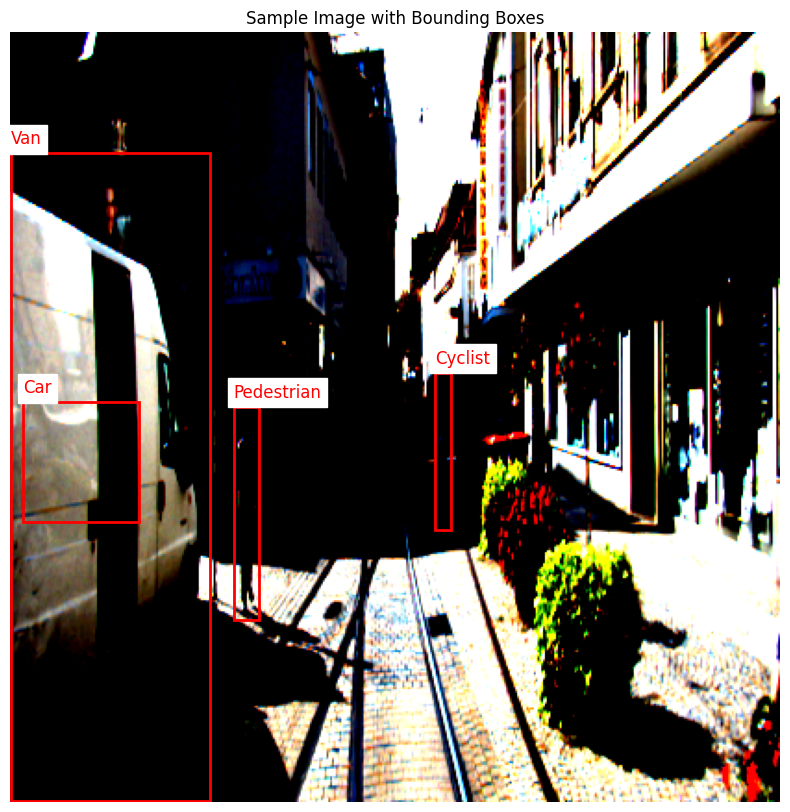

In [14]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

# Get an example
sample_image, sample_label = train_dataset[100]

boxes = sample_label['boxes']
labels = sample_label['labels']

# Convert image from tensor to NumPy
image_np = sample_image.permute(1, 2, 0).numpy()
# Normalized ---> Unnormalized
image_np = np.clip(image_np, 0, 1)

# Plot
fig, ax = plt.subplots(1, figsize=(10, 10))
ax.imshow(image_np)

# Draw bounding boxes
for box, label in zip(boxes, labels):
    x_min, y_min, x_max, y_max = box.tolist()
    width = x_max - x_min
    height = y_max - y_min

    rect = patches.Rectangle((x_min, y_min), width, height, linewidth=2, edgecolor='red', facecolor='none')
    ax.add_patch(rect)

    # Add label text
    label_id = int(label)
    for class_name, class_index in train_dataset.class_map.items():
        if class_index == label_id:
            ax.text(x_min, y_min - 5, class_name, color='red', fontsize=12, backgroundcolor='white')
            break

plt.axis('off')
plt.title("Sample Image with Bounding Boxes")
plt.show()




####5.   **Training Dataset and Validation Dataset**



In [15]:
def collate_fn(batch):
  images=[]
  targets=[]

  for img, target in batch:
    images.append(img)
    targets.append(target)

  images=torch.stack(images, dim=0)
  return images, targets

In [16]:
from torch.utils.data import ConcatDataset, random_split, DataLoader
# Augmentation
augment_transform = transforms.Compose([
    transforms.Resize(target_size),
    transforms.RandomRotation(10),  #Rotation until 10 degrees --relatively small
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.9, 1.1)),  # Moving off-center
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])
# Creating the Augmented Dataset
augmented_dataset = KITTIDataset(
    image_dir=image_dir,
    label_dir=label_dir,
    transform=augment_transform
)

train_dataset = KITTIDataset(image_dir=image_dir,
                            label_dir=label_dir,
                            transform=transform)

# Combine original and augmented training data
combined_dataset = ConcatDataset([train_dataset, augmented_dataset])

# Split combined dataset into training and validation sets (80/20)
train_size = int(0.8 * len(combined_dataset))
val_size = len(combined_dataset) - train_size
train_subset, val_subset = random_split(combined_dataset, [train_size, val_size])

# Create data loaders
batch_size = 32
train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True,num_workers=2, collate_fn=collate_fn)
val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False,num_workers=2,  collate_fn=collate_fn)

# Print dataset sizes
print(f"Augmented Dataset Size: {len(augmented_dataset)}")
print(f"Combined Dataset Size: {len(combined_dataset)}")
print(f"Training Subset Size: {len(train_subset)}")
print(f"Validation Subset Size: {len(val_subset)}")

Found (7481)PNG files in directory : training/image_2/
Found (7481)PNG files in directory : training/image_2/
Augmented Dataset Size: 7481
Combined Dataset Size: 14962
Training Subset Size: 11969
Validation Subset Size: 2993


**AUGMENTED TRANSFORMATION**

In this section a set of transformations are defined, which will be applied to the images in the dataset. These transformation are important for prepocesing of the images in preparing them for later **image classification**.
These tranformation improve the model's ability to recognize images that :

*) Are rotated 90 degrees

*) Are shifted and not in the center


<br><br>
**RELOADING THE DATASETS**

The KITTI dataset is loaded with the previously defined transformations applied.

▶ train_dataset --- train_transform

▶ augmneted_dataset --- augmented transform

<br><br>
**COMBINING THE DATASETS**

A dataset is created where the train and augmented datasets are merged in one. This will increase the help CNN learn/be trained by both datasets.

<br><br>
**DATALOADER**

Dataloader is a structure that loads and shuffles combined dataset in  a batch during the training process.

<br><br>

#**#4 DOWNLADING THE NEURAL NETWORK**

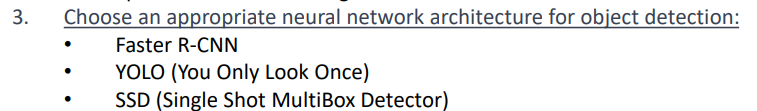

Downloading the pre-trained YOLO model

In [17]:
import torch.nn as nn
from torch import optim
import torch.nn.functional as F

class YOLO(nn.Module):
  def __init__(self, num_classes):
     super(YOLO, self).__init__()
     self.features=nn.Sequential(
         nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1),
         nn.ReLU(),
         nn.AdaptiveAvgPool2d((13,13))
     )
     self.classifier =nn.Linear(16*13*13, num_classes)

  def forward(self, x):
    x=self.features(x)
    x=x.view(x.size(0), -1)
    x=self.classifier(x)
    return x


#**#5 NEURAL NETWORK MODEL**

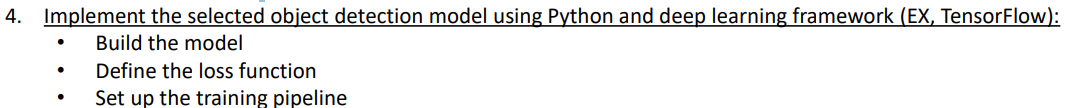

In [22]:
class YOLO_Loss(nn.Module):

    def __init__(self):
        super(YOLO_Loss, self).__init__()
        self.class_loss = nn.CrossEntropyLoss()

    def forward(self, predictions, targets):
        # targets is a list of dicts, each dict has 'labels'
        # predictions is a tensor of shape [batch_size, num_classes]
        # We will use only the first label per image for classification
        labels = []
        for t in targets:
            if t['labels'].numel() > 0:
                labels.append(t['labels'][0].item())
            else:
                labels.append(0)  # or -1 if you want to ignore
        labels = torch.tensor(labels, dtype=torch.long, device=predictions.device)
        return self.class_loss(predictions, labels)

In [23]:
"""
class YOLO_Loss(nn.Module):

  def __init__(self):
    super(YOLO_Loss,self).__init__()
    self.class_loss=nn.CrossEntropyLoss()
    self.bbox_loss=nn.MSELoss()


  def forward(self, predictions, targets):
    total_loss =0.0
    for pred, target in zip(predictions, targets):
      boxes=target['boxes']
      labels=target['labels']

      pred_boxes = pred['boxes']
      pred_labels=pred['labels']

      bbox_loss=self.bbox_loss(pred_boxes, boxes)

      clasf_loss=self.class_loss(pred_labels, labels)
      total_loss+= bbox_loss + clasf_loss

    return total_loss

    """

def train():
  # Hyperparameter Definitions
  num_classes=9 #(0 to 7  and -1 so =9)
  batch_size=32
  learning_rate=0.001
  epochs=10

  model = YOLO(num_classes)
  criterion = YOLO_Loss()
  optimizer = optim.Adam(model.parameters(), lr=learning_rate)

  # Loading the two datasets
  #train_subset=KITTIDataset(train =True)
  #val_subset=KITTIDataset(train=False)

  train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True, collate_fn=collate_fn)
  val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn)

  # Training performance measurements
  best_val_loss=float('inf')
  best_model_weights=None

  # Training loop
  for epoch in range(epochs):
      model.train()
      train_loss =0.0 # Initialize loss at zero

      for images, targets in train_loader:
          # Forward pass
          outputs = model(images)
          loss = criterion(outputs, targets)

          # Backward pass and optimize
          optimizer.zero_grad()
          loss.backward()
          optimizer.step()

          train_loss +=loss.item() # Update loss

      # Validation
      model.eval()
      val_loss = 0.0
      with torch.no_grad():
          for images, targets in val_loader:
              outputs = model(images)
              val_loss += criterion(outputs, targets).item()

      avg_train_loss=train_loss/len(train_loader)
      avg_val_loss=val_loss/len(val_loader)

      print(f'Epoch Number [{epoch+1}/{epochs}], Training Loss: {loss.item():.4f}, Validation Loss: {val_loss/len(val_loader):.4f}')

      if avg_val_loss < best_val_loss:
          best_val_loss = avg_val_loss
          best_model_weights = model.state_dict().copy()  # Save a copy of the weights
          torch.save(best_model_weights, 'best_model.pth')
          print(f"New best model saved with val loss: {best_val_loss:.4f}")

  # Load the best model weights
  model.load_state_dict(torch.load('best_model.pth'))
  print(f"Training has been completed. Best validation loss: {best_val_loss:.4f}")

  return model

In [24]:
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')  

#**#6 TRAINING THE DATASET**

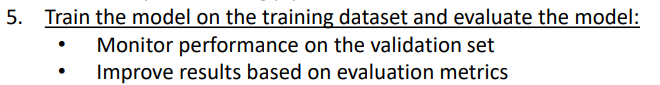

In [25]:
trained_model=train()

Epoch Number [1/10], Training Loss: 0.3528, Validation Loss: 0.5572
New best model saved with val loss: 0.5572
Epoch Number [2/10], Training Loss: 1.7095, Validation Loss: 0.5082
New best model saved with val loss: 0.5082
Epoch Number [3/10], Training Loss: 0.1632, Validation Loss: 0.4645
New best model saved with val loss: 0.4645
Epoch Number [4/10], Training Loss: 0.0897, Validation Loss: 0.4514
New best model saved with val loss: 0.4514
Epoch Number [5/10], Training Loss: 0.3005, Validation Loss: 0.3884
New best model saved with val loss: 0.3884
Epoch Number [6/10], Training Loss: 0.0156, Validation Loss: 0.4014
Epoch Number [7/10], Training Loss: 0.0570, Validation Loss: 0.3913
Epoch Number [8/10], Training Loss: 0.0142, Validation Loss: 0.3784
New best model saved with val loss: 0.3784
Epoch Number [9/10], Training Loss: 0.0031, Validation Loss: 0.3522
New best model saved with val loss: 0.3522
Epoch Number [10/10], Training Loss: 0.1747, Validation Loss: 0.3588
Training has been 

#**#7 TESTING THE  DATSET**

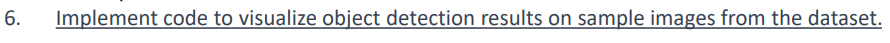

Image was found at path: /Users/jonidazekaj/Documents/Final Submission/HW6/testing/image_2/000101.png


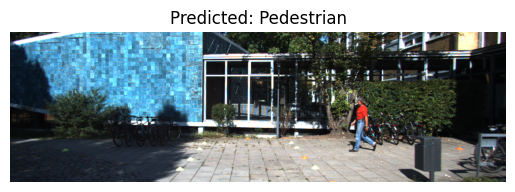

In [34]:
num_classes=9
model=YOLO(num_classes)
model.load_state_dict(torch.load('best_model.pth'))
model.eval()

image_path ='/Users/jonidazekaj/Documents/Final Submission/HW6/testing/image_2/000101.png'  # Change to any image in the directory
if not os.path.exists(image_path):
    print(f"Image was not found at path: {image_path}")
else:
    print(f"Image was found at path: {image_path}")
    image= cv2.imread(image_path)
img_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
img_resized = cv2.resize(img_rgb, (224,224))  # resize to model input
tensor = torch.tensor(img_resized/255., dtype=torch.float32).permute(2,0,1).unsqueeze(0)

with torch.no_grad():
    outputs=model(tensor)
    _, pred=outputs.max(1)

class_names = ["Car", "Pedestrian", "Cyclist", "Truck", "Van", "Tram", "Misc", "DontCare", "Background"]
pred_label = class_names[pred.item()]

# Show image with predicted class
plt.imshow(img_rgb)
plt.title(f"Predicted: {pred_label}")
plt.axis("off")
plt.show()